# Initial EDA
The initial EDA of the dataset allows to capture the shape of the data, identifiy missing values and other values which would have to be converted for later usage in a secondary eda on the data before modelling. 

### 1 Initial Analytics

#### 1.1 Data Loading
The Data and Dictionary are loaded into the notebook for usage throughout the EDA, both are loaded into a pandas dataframe. 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

#Load data into pandas dataframe
data = pd.read_csv("../data/preprocessed/global_health_dataset.csv")
dictionary = pd.read_csv("../data/preprocessed/dictionary.csv")

print(data.shape)
print(data["iso3"].nunique(), "countries,", data["year"].min(), "-", data["year"].max())
data.head()

(4440, 304)
185 countries, 2000 - 2023


,iso3,country,region,income_group,year,air_pollution_mortality,alcohol_per_capita,avail_ace_inhibitors,avail_breast_screening,avail_bronchodilators,...,death_asdr_trichuriasis,death_asdr_trypanosomiasis,death_asdr_tuberculosis,death_asdr_uncorrected_refractive_errors,death_asdr_unintentional_injuries,death_asdr_upper_respiratory_infections,death_asdr_urolithiasis,death_asdr_vitamin_a_deficiency,death_asdr_whooping_cough,death_asdr_yellow_fever
0,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2000,NaN,0.003389,NaN,NaN,NaN,...,0.0,0.0,142.008125,0.0,124.627585,0.041915,0.247705,0.0,4.942152,0.0
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2001,NaN,0.003389,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2002,NaN,0.003953,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2003,NaN,0.005955,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2004,NaN,0.008933,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### 1.2 Yearly Data overview

To asses the shape of the data, rows and columns are counted and grouped by year and visualised in a bar chart. 

year
2000    0.87
2001    0.14
2002    0.15
2003    0.15
2004    0.15
2005    0.15
2006    0.15
2007    0.16
2008    0.16
2009    0.16
2010    0.90
2011    0.16
2012    0.16
2013    0.21
2014    0.16
2015    0.92
2016    0.17
2017    0.20
2018    0.16
2019    0.92
2020    0.87
2021    0.91
2022    0.87
2023    0.87
dtype: float64


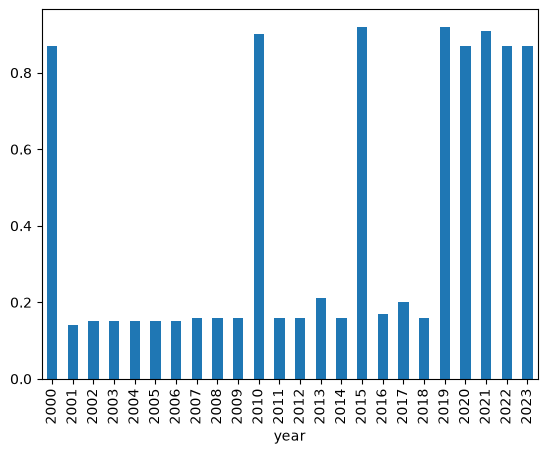

In [10]:
value_cols = dictionary["column"]
year_shape = data.groupby("year")[value_cols].apply(lambda g: g.notna().mean().mean()).round(2); 

#Chart
year_shape.plot(kind="bar")
print(year_shape)

In [12]:
dictionary["group"].value_counts()

group
cause_of_death            214
system_input               18
treatment_availability     17
system_output              16
risk_factor                12
outcome                    11
context                    10
data_quality                1
Name: count, dtype: int64

### Missing Values

Nextly, the dataset is checked for missing values. 

In [15]:
missing = pd.DataFrame({
    "missing_all_years": data.isna().mean(),
    "missing_2019": data[data["year"] == 2019].isna().mean(),
})
missing = missing.join(dictionary.set_index("column")["group"])
missing = missing.sort_values("missing_2019", ascending=False)
missing.head(30)

,missing_all_years,missing_2019,group
tobacco_prevalence,0.709910,1.000000,risk_factor
death_registration_completeness,0.910586,1.000000,data_quality
caesarean_rate,0.962387,1.000000,system_output
psychiatrists_per100k,0.968018,1.000000,system_input
radiotherapy_per1m,0.894369,1.000000,system_input
raised_glucose_prevalence,0.388514,1.000000,risk_factor
telecobalt_per1m,0.928604,1.000000,system_input
avail_diabetes_testing,0.962838,1.000000,treatment_availability
linear_accelerator_per1m,0.927703,1.000000,system_input
mean_bmi,0.306982,1.000000,risk_factor


In [18]:
sparse = missing[(missing["missing_2019"] > 0.2) & (missing["group"] != "cause_of_death")].index

rows = []
for col in sparse:
    has_value = data[data[col].notna() & (data["year"] <= 2019)]
    rows.append({
        "column": col,
        "countries_2015_2019": has_value.loc[has_value["year"] >= 2015, "iso3"].nunique(),
        "countries_2013_2019": has_value.loc[has_value["year"] >= 2013, "iso3"].nunique(),
    })
pd.DataFrame(rows).sort_values("countries_2013_2019", ascending=False)

,column,countries_2015_2019,countries_2013_2019
25,nurses_per10k,179,182
28,doctors_per10k,176,182
5,raised_glucose_prevalence,0,181
9,mean_bmi,181,181
10,ihr_capacity,171,180
26,dentists_per10k,172,177
24,pharmacists_per10k,167,174
22,skilled_birth_attendance,153,167
14,avail_breast_screening,0,165
7,avail_diabetes_testing,0,165


In [20]:
cause_cols = dictionary.loc[dictionary["group"] == "cause_of_death", "column"]
causes_2019 = data.loc[data["year"] == 2019, cause_cols]

cause_summary = pd.DataFrame({
    "share_zero": (causes_2019 == 0).mean(), # share of countries with exactly 0 deaths
    "median_rate": causes_2019.median(), # deaths per 100,000
    "max_rate": causes_2019.max(),
}).sort_values("median_rate")

print((cause_summary["share_zero"] == 1).sum(), "causes have 0 deaths in every country")
print((cause_summary["median_rate"] < 0.1).sum(), "causes have a median below 0.1 per 100,000")
cause_summary.head(40)

17 causes have 0 deaths in every country
77 causes have a median below 0.1 per 100,000


,share_zero,median_rate,max_rate
death_asdr_gential_herpes,1.000000,0.0,0.000000
death_asdr_trichomoniasis,1.000000,0.0,0.000000
death_asdr_trypanosomiasis,0.908108,0.0,4.582637
death_asdr_malaria,0.632432,0.0,98.858119
death_asdr_leishmaniasis,0.632432,0.0,5.139212
death_asdr_lymphatic_filariasis,0.983784,0.0,0.055273
death_asdr_schistosomiasis,0.610811,0.0,13.174512
death_asdr_chagas_disease,0.875676,0.0,10.808234
death_asdr_trichuriasis,1.000000,0.0,0.000000
death_asdr_hookworm_disease,0.989189,0.0,0.009609


#### 5
AHHHHHHH

In [21]:
drop_causes = cause_summary[(cause_summary["share_zero"] >= 0.9) | (cause_summary["max_rate"] < 0.5)].index

print(len(drop_causes), "causes dropped,", len(cause_cols) - len(drop_causes), "kept")
print(sorted(c.replace("death_asdr_", "") for c in drop_causes))

42 causes dropped, 172 kept
['anxiety_disorders', 'attention_deficit_hyperactivity_syndrome', 'austism_and_asperger_syndrome', 'bipolar_disorder', 'cannabis_use_disorders', 'cataracts', 'childhood_behavioural_disorders', 'chlamydia', 'cleft_lip_and_cleft_palate', 'conduct_disorder', 'covid_19', 'dental_caries', 'depressive_disorders', 'eating_disorders', 'echinococcosis', 'edentulism', 'gential_herpes', 'glaucoma', 'gonorrhoea', 'hookworm_disease', 'infertility', 'iodine_deficiency', 'leprosy', 'lymphatic_filariasis', 'macular_degeneration', 'migraine', 'non_migrane_headache', 'onchocerciasis', 'oral_conditions', 'other_hearing_loss', 'other_mental_and_behavioural_disorders', 'other_oral_disorders', 'other_sense_organ_disorders', 'other_vision_loss', 'periodontal_disease', 'sense_organ_diseases', 'trachoma', 'trichomoniasis', 'trichuriasis', 'trypanosomiasis', 'uncorrected_refractive_errors', 'vitamin_a_deficiency']


In [22]:
drop_indicators = [
    "mri_per1m", "caesarean_rate", "gamma_camera_per1m", "pet_per1m", "hpv_coverage",   # < 75% of countries
    "avail_chemotherapy", "air_pollution_mortality",                                     # no data up to 2019
    "linear_accelerator_per1m", "telecobalt_per1m",                                      # parts of radiotherapy_per1m
    "death_registration_completeness",                                                   # kept aside, not a network variable
]
keep_cols = [c for c in dictionary["column"] if c not in drop_indicators and c not in drop_causes]
print(len(keep_cols), "columns kept")

# skewness in 2019 (> 1 = strongly right-skewed, usually a candidate for a log transform)
skew = data.loc[data["year"] == 2019, keep_cols].skew().sort_values(ascending=False)
print((skew > 1).sum(), "of", len(skew), "columns have skewness > 1")
skew.head(15)

247 columns kept
152 of 247 columns have skewness > 1


death_asdr_natural_disasters                          13.552500
death_asdr_food_borne_trematodes                      13.477220
death_asdr_gout                                       12.997013
death_asdr_ascariasis                                 10.294960
death_asdr_diphtheria                                 10.062448
death_asdr_cocaine_use_disorders                       9.939038
death_asdr_liver_cancer_secondary_to_hepatitis_c       9.554307
death_asdr_chagas_disease                              9.390689
death_asdr_intestinal_nematode_infections              9.387771
death_asdr_acute_hepatitis_c                           9.179610
death_asdr_leishmaniasis                               8.830421
death_asdr_liver_cancer                                8.672439
death_asdr_tetanus                                     8.535804
population                                             8.194845
death_asdr_cardiomyopathy_myocarditis_endocarditis     7.761296
dtype: float64

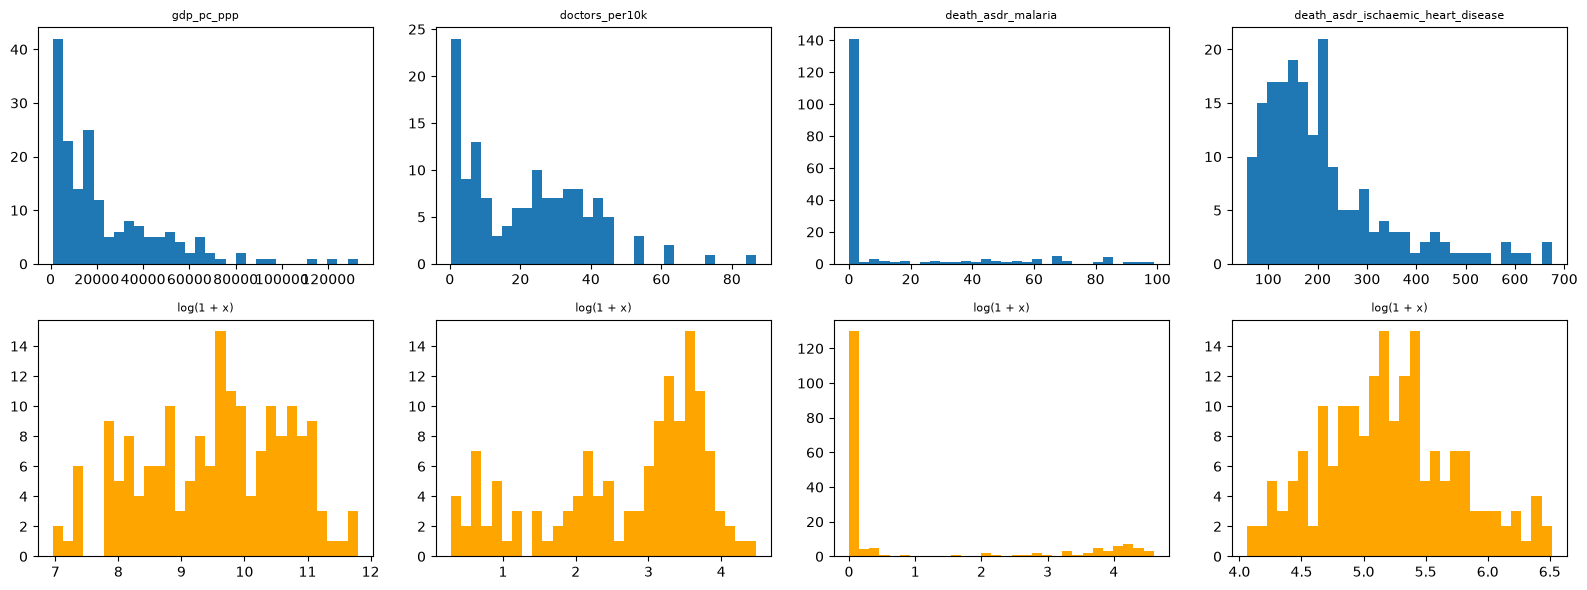

In [24]:
import numpy as np

examples = ["gdp_pc_ppp", "doctors_per10k", "death_asdr_malaria", "death_asdr_ischaemic_heart_disease"]
d2019 = data[data["year"] == 2019]

fig, axes = plt.subplots(2, len(examples), figsize=(16, 6))
for i, col in enumerate(examples):
    axes[0, i].hist(d2019[col].dropna(), bins=30)
    axes[0, i].set_title(col, fontsize=8)
    axes[1, i].hist(np.log1p(d2019[col].dropna()), bins=30, color="orange")
    axes[1, i].set_title("log(1 + x)", fontsize=8)
plt.tight_layout()
plt.show()

In [27]:
#group causes
group_causes = [
    "all_causes", "communicable_maternal_perinatal_and_nutritional_conditions",
    "infectious_and_parasitic_diseases", "stds_excluding_hiv", "childhood_cluster_diseases",
    "hepatitis", "parasitic_and_vector_diseases", "intestinal_nematode_infections",
    "respiratory_infectious", "neonatal_conditions", "nutritional_deficiencies",
    "noncommunicable_diseases", "malignant_neoplasms", "mouth_and_oropharynx_cancers",
    "liver_cancer", "melanoma_and_other_skin_cancers", "lymphomas_multiple_myeloma",
    "endocrine_blood_immune_disorders", "mental_and_substance_use_disorders",
    "drug_use_disorders", "childhood_behavioural_disorders", "neurological_conditions",
    "sense_organ_diseases", "cardiovascular_diseases", "stroke", "respiratory_diseases",
    "digestive_diseases", "cirrhosis_of_the_liver", "genitourinary_diseases", "kidney_diseases",
    "musculoskeletal_diseases", "congenital_anomalies", "oral_conditions",
    "injuries", "unintentional_injuries", "intentional_injuries",
]
group_cols = ["death_asdr_" + g for g in group_causes]

# sanity check: a group should equal the sum of its parts (here: cardiovascular diseases, 2019)
cvd_parts = ["rheumatic_heart_disease", "hypertensive_heart_disease", "ischaemic_heart_disease",
             "stroke", "cardiomyopathy_myocarditis_endocarditis", "other_circulatory_diseases"]
gap = (d2019[["death_asdr_" + p for p in cvd_parts]].sum(axis=1) - d2019["death_asdr_cardiovascular_diseases"]).abs().max()
print("max difference CVD group vs parts:", round(gap, 4))

leaf_causes = [c for c in cause_cols if c not in group_cols and c not in drop_causes]
print(len(leaf_causes), "causes used as network nodes")

max difference CVD group vs parts: 0.0
139 causes used as network nodes


state stuff

In [30]:
indicator_cols = dictionary.loc[dictionary["group"] != "cause_of_death", "column"].tolist()
indicator_keep = [c for c in indicator_cols if c not in drop_indicators]

recent = data[data["year"].between(2013, 2019)].sort_values("year")
latest = recent.groupby("country")[indicator_keep].last()   # latest non-missing value per country
latest["battle_deaths"] = latest["battle_deaths"].fillna(0)

missing_per_country = latest.isna().mean(axis=1).sort_values(ascending=False)
print(len(indicator_keep), "indicators,", len(latest), "countries")
print((missing_per_country > 0.2).sum(), "countries miss more than 20% of indicators")
missing_per_country.head(20).round(2)

75 indicators, 185 countries
3 countries miss more than 20% of indicators


country
Puerto Rico (US)                  0.72
West Bank and Gaza                0.39
Korea, Dem. People's Rep.         0.23
South Sudan                       0.16
St. Vincent and the Grenadines    0.15
Equatorial Guinea                 0.13
Congo, Dem. Rep.                  0.11
Micronesia, Fed. Sts.             0.11
Eritrea                           0.09
Sudan                             0.08
Haiti                             0.08
Chad                              0.08
Angola                            0.08
Venezuela, RB                     0.08
Timor-Leste                       0.08
Sierra Leone                      0.08
Somalia, Fed. Rep.                0.08
Djibouti                          0.07
Solomon Islands                   0.07
Nicaragua                         0.07
dtype: float64